# Diffusion of N particles in a box

Course assignment. Particles diffuse on a square lattice in a closed box (periodic boundaries) or in an infinite pool (particles enter from the walls and can leave). The questions are the ones given in the assignment. The functions in `diffusion_box.py` and `libplot_diff.py` were provided by the course.

Q1. Observe the equilibrium in CLOSED BOX. What does it mean to "reach equilibrium"? How can i indentify it in a closed box or in an infinite pool box? Use graphs, numbers, statistics to make your point.

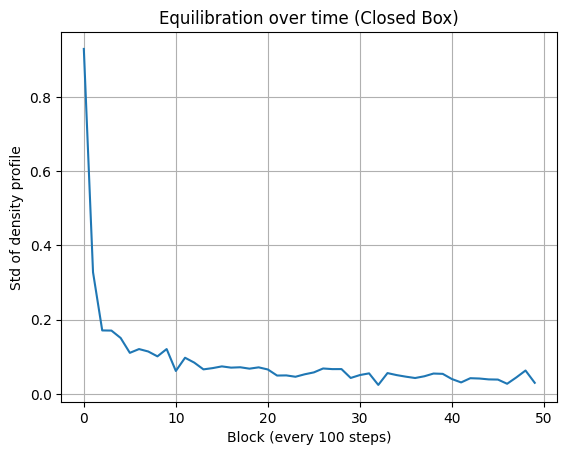

Initial std: 0.929
Final std: 0.03


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import diffusion_box as db
import libplot_diff as dl

N = 100
L = 100
resol = 50
averages = 100

CLOSED_BOX = True
std_history = []  


if CLOSED_BOX:
    coord = db.create_in_point(N, [int(L/2), int(L/2)])
else:
    coord = db.create(N, L)

px_acc = np.zeros(resol)
k = 0

for step in range(5000):
    coord = db.diffusione(coord)
    if CLOSED_BOX:
        coord = db.p_boundary(coord, L)
    else:
        coord = db.check(coord, L)
        coord = np.vstack((coord, db.create(N, L)))

    k += 1
    _, prof_x, _ = dl.density(coord, resol, L)
    px_acc += prof_x / averages

    if k % averages == 0:
        std_history.append(np.std(px_acc))
        px_acc = np.zeros(resol)

plt.figure()
plt.plot(std_history)
plt.xlabel("Block (every 100 steps)")
plt.ylabel("Std of density profile")
plt.title("Equilibration over time (Closed Box)" if CLOSED_BOX else "Equilibration over time (Infinite Pool)")
plt.grid(True)
plt.show()

print("Initial std:", round(std_history[0], 3))
print("Final std:", round(std_history[-1], 3))

To understand what equilibrium means I looked at how the density profile changes over time. At the beginning in the closed box all the particles are in the centre so the profile has a big spike in the middle. As the simulation runs the particles start spreading out and the spike slowly flattens. I used the standard deviation of the profile to measure this — when the std stopped decreasing and stayed at a low stable value I considered that equilibrium was reached. In the plot above the std drops from 0.93 very quickly at first and levels off at about 0.05–0.07 after roughly 1000–1500 steps. After that it only fluctuates.

For the infinite pool it is different because particles are always entering from the walls and leaving again, so the number of particles is not fixed. The system is always exchanging particles with the outside, so the stable state it goes towards is a steady state and not an equilibrium. To identify it I have to look at two things, the std of the profile and the number of particles in the box, and both must stop changing (see question 4).

Q2: How much time is needed to reach the equilibrium in the CLOSED box? What is the dependence of this time from the parameters you have set? Measure it and see its dependence on the input parameters (e.g. N, L ....).

N=50, equilibration time: 100 steps
N=100, equilibration time: 100 steps
N=200, equilibration time: 200 steps
N=500, equilibration time: 200 steps


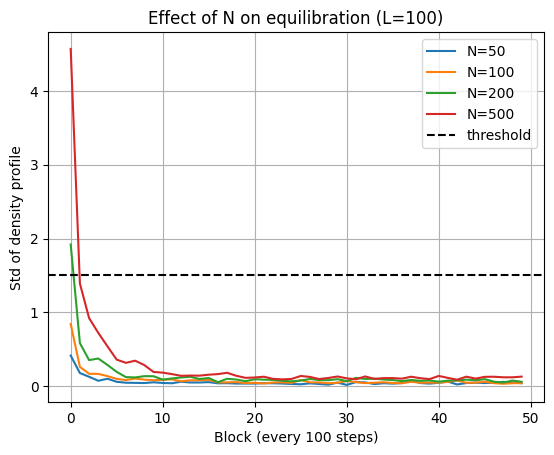

L=50, equilibration time: 100 steps
L=100, equilibration time: 100 steps
L=200, equilibration time: 200 steps


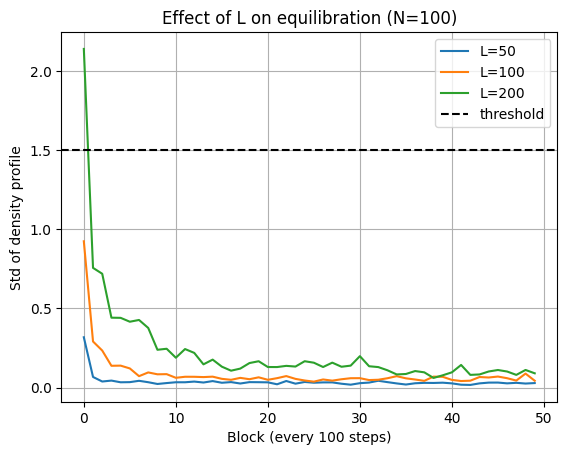

In [5]:
THRESHOLD = 1.5

def run_simulation(N, L, nsteps=5000, averages=100, resol=50):
    """runs the closed box simulation and returns the std history"""
    coord = db.create_in_point(N, [int(L/2), int(L/2)])
    px_acc = np.zeros(resol)
    std_history = []
    k = 0
    for step in range(nsteps):
        coord = db.diffusione(coord)
        coord = db.p_boundary(coord, L)
        k += 1
        _, prof_x, _ = dl.density(coord, resol, L)
        px_acc += prof_x / averages
        if k % averages == 0:
            std_history.append(np.std(px_acc))
            px_acc = np.zeros(resol)
    return std_history

def find_equil_time(std_history, threshold, averages):
    """returns the step at which std drops below threshold"""
    for i, std in enumerate(std_history):
        if std < threshold:
            return (i + 1) * averages
    return None

N_values = [50, 100, 200, 500]
L = 100
resol = 50
averages = 100

plt.figure()
equil_times_N = []
for N in N_values:
    std_history = run_simulation(N, L, resol=resol, averages=averages)
    t = find_equil_time(std_history, THRESHOLD, averages)
    equil_times_N.append(t)
    plt.plot(std_history, label=f"N={N}")
    print(f"N={N}, equilibration time: {t} steps")

plt.axhline(THRESHOLD, color='black', ls='--', label='threshold')
plt.xlabel("Block (every 100 steps)")
plt.ylabel("Std of density profile")
plt.title("Effect of N on equilibration (L=100)")
plt.legend()
plt.grid(True)
plt.show()

N = 100
L_values = [50, 100, 200]

plt.figure()
equil_times_L = []
for L in L_values:
    std_history = run_simulation(N, L, resol=resol, averages=averages)
    t = find_equil_time(std_history, THRESHOLD, averages)
    equil_times_L.append(t)
    plt.plot(std_history, label=f"L={L}")
    print(f"L={L}, equilibration time: {t} steps")

plt.axhline(THRESHOLD, color='black', ls='--', label='threshold')
plt.xlabel("Block (every 100 steps)")
plt.ylabel("Std of density profile")
plt.title("Effect of L on equilibration (N=100)")
plt.legend()
plt.grid(True)
plt.show()

To figure out how long it takes to reach equilibrium I used the same std method from question 1 and counted how many steps it took for the std to drop below a fixed value (1.5). I tested different values of N and L.

Looking at the results, this threshold was not a good choice. For N=50 and N=100 the std is already below 1.5 in the first block, so the printed time of 100 steps only means "the first block". For N=200 and N=500 the curve starts higher, simply because the height of the profile is proportional to the number of particles, so it crosses the threshold one block later. So the printed times do not really measure the equilibration time, and they should not be read as "more particles is slower".

The curves themselves are more useful. For all four values of N the std flattens after roughly the same number of steps (about 1000). This is what I expect, because in this simulation the particles do not interact, so each one spreads in the same way no matter how many others there are.

For L the curves show a real difference: for L=50 the std is flat almost immediately, for L=100 it flattens after about 1000 steps, and for L=200 it needs about 1500–2000 steps and stays noisier. So a bigger box takes longer to equilibrate, which makes sense because the particles all start in the middle and have to spread over a larger distance. Since the distance a diffusing particle covers grows like the square root of the number of steps, I expect the time to grow like L², but my threshold is too coarse to check this. A better method would be to divide the std by N and to use a threshold relative to the starting value.

Q3: Set the particle initially in a line instead of a point at the centre. Suggestion: you have to create function that set "coord" array of (x,y) coordinates to the wanted coordinates. Propose a starting situation that minimize the equilibration time

Point (centre): equilibration time = 100 steps
Horizontal line: equilibration time = 100 steps
Vertical line: equilibration time = 100 steps
Diagonal line: equilibration time = 100 steps


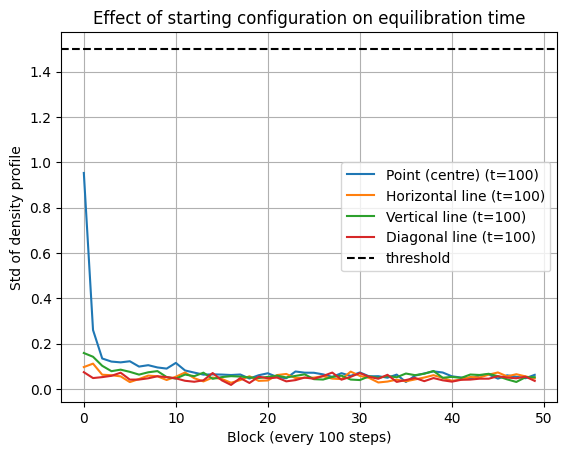

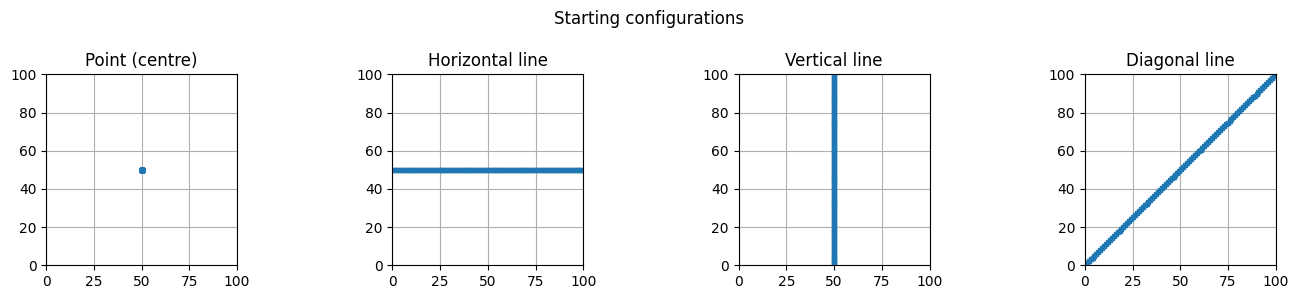

In [7]:
N = 100
L = 100
resol = 50
averages = 100
THRESHOLD = 1.5

def run_simulation(coord, nsteps=5000, averages=100, resol=50):
    """runs the closed box simulation from a given starting coord and returns std history"""
    px_acc = np.zeros(resol)
    std_history = []
    k = 0
    for step in range(nsteps):
        coord = db.diffusione(coord)
        coord = db.p_boundary(coord, L)
        k += 1
        _, prof_x, _ = dl.density(coord, resol, L)
        px_acc += prof_x / averages
        if k % averages == 0:
            std_history.append(np.std(px_acc))
            px_acc = np.zeros(resol)
    return std_history

def find_equil_time(std_history, threshold, averages):
    for i, std in enumerate(std_history):
        if std < threshold:
            return (i + 1) * averages
    return None


coord_point = db.create_in_point(N, [int(L/2), int(L/2)])

x_coords = np.linspace(0, L, N)
y_coords = np.full(N, L/2)
z_coords = np.zeros(N)
coord_hline = np.column_stack((x_coords, y_coords, z_coords))

# 3. vertical line through the centre
x_coords = np.full(N, L/2)
y_coords = np.linspace(0, L, N)
z_coords = np.zeros(N)
coord_vline = np.column_stack((x_coords, y_coords, z_coords))

x_coords = np.linspace(0, L, N)
y_coords = np.linspace(0, L, N)
z_coords = np.zeros(N)
coord_diag = np.column_stack((x_coords, y_coords, z_coords))

configs = {
    "Point (centre)":    coord_point,
    "Horizontal line":   coord_hline,
    "Vertical line":     coord_vline,
    "Diagonal line":     coord_diag,
}

plt.figure()
for name, coord in configs.items():
    std_history = run_simulation(coord.copy())
    t = find_equil_time(std_history, THRESHOLD, averages)
    plt.plot(std_history, label=f"{name} (t={t})")
    print(f"{name}: equilibration time = {t} steps")

plt.axhline(THRESHOLD, color='black', ls='--', label='threshold')
plt.xlabel("Block (every 100 steps)")
plt.ylabel("Std of density profile")
plt.title("Effect of starting configuration on equilibration time")
plt.legend()
plt.grid(True)
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, (name, coord) in zip(axes, configs.items()):
    ax.plot(coord[:,0], coord[:,1], 's', markersize=3)
    ax.set_xlim(0, L)
    ax.set_ylim(0, L)
    ax.set_title(name)
    ax.set_aspect('equal')
    ax.grid(True)
plt.suptitle("Starting configurations")
plt.tight_layout()
plt.show()

For this question I tried different starting configurations for the particles instead of always starting from a single point. I tested four cases: a point in the centre, a horizontal line, a vertical line, and a diagonal line. To compare them I used the same std method from before.

The printed equilibration times are 100 steps for all four cases, so with my threshold (1.5) I cannot tell them apart: every curve is below the threshold from the first block. The curves in the plot do show a difference. The point in the centre starts with a high std (about 0.95) and needs about 1000 steps to come down to the level of the others. This makes sense because the particles are all squeezed into one spot and need to spread out in every direction. The three line configurations start much lower (below 0.2) and reach the plateau within a few hundred steps, because the particles are already spread out in at least one direction. The measure I use only looks at the profile through the middle of the box, so the small differences between the three lines at the start are not a reliable ranking.

So I think the best starting configuration to minimise the equilibration time is one where the particles are already as spread out as possible across the box, for example at random positions over the whole box, because then the profile is flat from the start. I did not test that case here.

Q4: do tasks (1) and (2) for the OPEN BOX

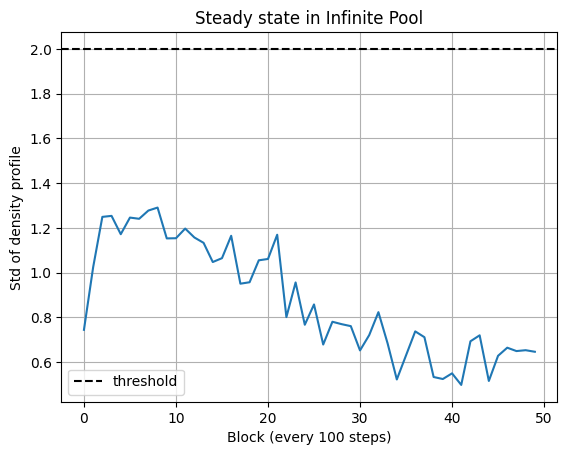

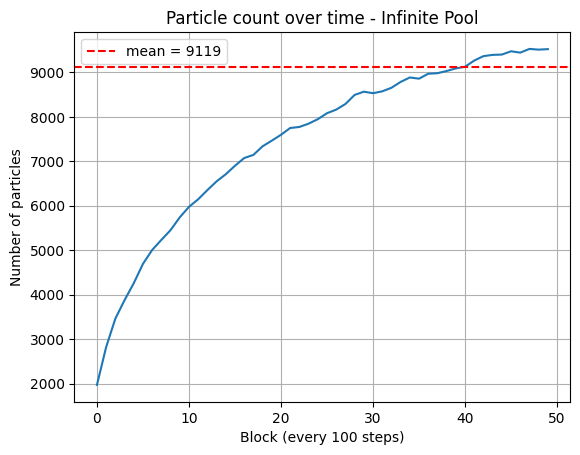

Initial std: 0.744
Final std: 0.646
Mean particle count (last 20 blocks): 9119.0
N=50, steady-state time: 100 steps
N=100, steady-state time: 100 steps
N=200, steady-state time: 100 steps
N=500, steady-state time: 4400 steps


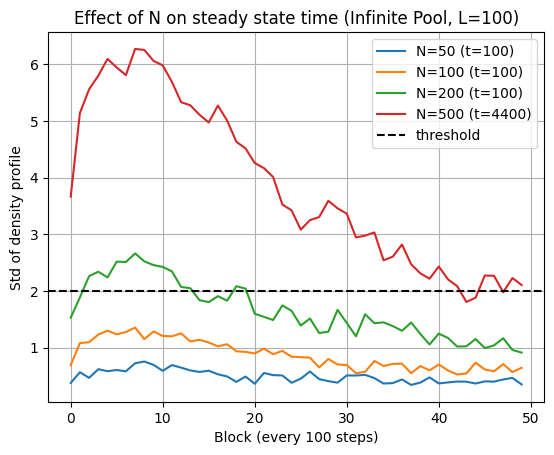

L=50, steady-state time: 100 steps
L=100, steady-state time: 100 steps
L=200, steady-state time: 100 steps


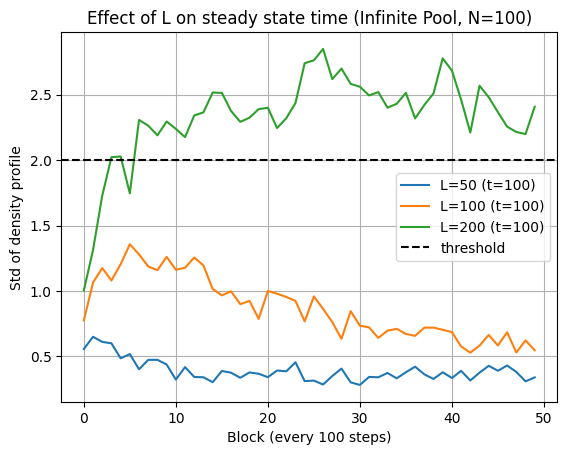

In [8]:
N = 100
L = 100
resol = 50
averages = 100
THRESHOLD = 2.0 


coord = db.create(N, L)
px_acc = np.zeros(resol)
std_history = []
np_history = []
k = 0

for step in range(5000):
    coord = db.diffusione(coord)
    coord = db.check(coord, L)
    coord = np.vstack((coord, db.create(N, L)))
    k += 1
    _, prof_x, _ = dl.density(coord, resol, L)
    px_acc += prof_x / averages
    if k % averages == 0:
        std_history.append(np.std(px_acc))
        np_history.append(len(coord))
        px_acc = np.zeros(resol)

plt.figure()
plt.plot(std_history)
plt.axhline(THRESHOLD, color='black', ls='--', label='threshold')
plt.xlabel("Block (every 100 steps)")
plt.ylabel("Std of density profile")
plt.title("Steady state in Infinite Pool")
plt.legend()
plt.grid(True)
plt.show()

plt.figure()
plt.plot(np_history)
plt.axhline(np.mean(np_history[-20:]), color='red', ls='--',
            label=f'mean = {np.mean(np_history[-20:]):.0f}')
plt.xlabel("Block (every 100 steps)")
plt.ylabel("Number of particles")
plt.title("Particle count over time - Infinite Pool")
plt.legend()
plt.grid(True)
plt.show()

print("Initial std:", round(std_history[0], 3))
print("Final std:", round(std_history[-1], 3))
print("Mean particle count (last 20 blocks):", round(np.mean(np_history[-20:]), 1))


def run_simulation_open(N, L, nsteps=5000, averages=100, resol=50):
    coord = db.create(N, L)
    px_acc = np.zeros(resol)
    std_history = []
    k = 0
    for step in range(nsteps):
        coord = db.diffusione(coord)
        coord = db.check(coord, L)
        coord = np.vstack((coord, db.create(N, L)))
        k += 1
        _, prof_x, _ = dl.density(coord, resol, L)
        px_acc += prof_x / averages
        if k % averages == 0:
            std_history.append(np.std(px_acc))
            px_acc = np.zeros(resol)
    return std_history

def find_equil_time(std_history, threshold, averages):
    for i, std in enumerate(std_history):
        if std < threshold:
            return (i + 1) * averages
    return None

N_values = [50, 100, 200, 500]
L = 100

plt.figure()
for N in N_values:
    std_history = run_simulation_open(N, L)
    t = find_equil_time(std_history, THRESHOLD, averages)
    plt.plot(std_history, label=f"N={N} (t={t})")
    print(f"N={N}, steady-state time: {t} steps")

plt.axhline(THRESHOLD, color='black', ls='--', label='threshold')
plt.xlabel("Block (every 100 steps)")
plt.ylabel("Std of density profile")
plt.title("Effect of N on steady state time (Infinite Pool, L=100)")
plt.legend()
plt.grid(True)
plt.show()

N = 100
L_values = [50, 100, 200]

plt.figure()
for L in L_values:
    std_history = run_simulation_open(N, L)
    t = find_equil_time(std_history, THRESHOLD, averages)
    plt.plot(std_history, label=f"L={L} (t={t})")
    print(f"L={L}, steady-state time: {t} steps")

plt.axhline(THRESHOLD, color='black', ls='--', label='threshold')
plt.xlabel("Block (every 100 steps)")
plt.ylabel("Std of density profile")
plt.title("Effect of L on steady state time (Infinite Pool, N=100)")
plt.legend()
plt.grid(True)
plt.show()

For this question I repeated the same analysis from questions 1 and 2 but this time for the infinite pool. The behaviour is quite different from the closed box. In the closed box the number of particles stays constant and the profile becomes flat at equilibrium. In the infinite pool new particles enter from the walls at every step and others leave, so the number of particles is not fixed. In my run it grows from about 2000 to about 9500 during the 5000 steps and it is still increasing at the end, so the system has not reached its steady state yet in this run. The std of the profile first goes up and then slowly comes down (final value 0.65, compared with 0.03 in the closed box), so the profile is still not flat: the particles are injected at the walls and need time to reach the centre. To see the real steady state I would need a longer simulation, and I would check that both the particle count and the std stop changing.

I would not call that final state equilibrium but a steady state, where things stop changing on average but the system is still constantly exchanging particles with the outside.

For the dependence on N and L the threshold method did not work here. The printed time is 100 steps in almost every case only because the std starts below the threshold. For N=200, N=500 and L=200 the std first rises above the threshold, which my function does not handle: it gives 100 steps for N=200 and L=200 and 4400 steps for N=500, although the L=200 curve stays above the threshold for the rest of the run. So from these results I cannot say how the time to reach the steady state depends on N and L. What the curves do show is that the std is larger for larger N and for larger L, and that for L=200 it has not started to come down within 5000 steps, which is consistent with a bigger box needing more time to fill.

Overall I think the main difference between the two cases is that the closed box reaches a true equilibrium with a flat profile, while the infinite pool goes towards a steady state driven by the constant flow of particles from the boundary.